# Module 2: Appreciating, Interpreting and Visualizing Data
## Lab 1: Basic Plots
---

# Introduction: Why Visualize Data?

It is often said, **"Data is only as good as it is presented."** Countless studies show how our brain is wired for the visual, processing images and patterns far faster than tables of numbers. Before we write a single line of code for a complex machine learning model, **visualizing the data is a critical first step**. It allows us to:

- Appreciate the scale and scope of our data.
- Interpret relationships, patterns, and distributions within the data.
- Visualize potential problems like outliers or missing values.

In this lab, you will learn simple yet powerful ways to **visualize your data using Python's most popular libraries**. Understanding these plots will help you decode the various features in a dataset and understand their impact on what you are trying to predict.



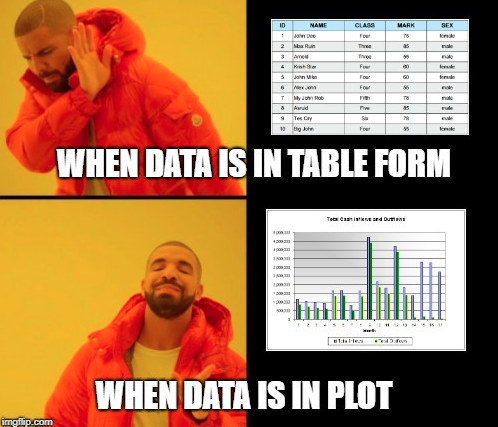

## Our Toolkit: Matplotlib and Seaborn

Data visualizations in Python can be done via many packages. We’ll start with **Matplotlib**, the foundational plotting library, and then move to **Seaborn**, which is built on top of Matplotlib and allows us to create more statistically-focused and aesthetically pleasing plots with less code.  

- **Matplotlib:**  
  It is a robust 2D plotting library that provides a high degree of control over every aspect of a figure. It's like having a full box of crayons, where you can draw and customize anything you want.

- **Seaborn:**  
  This is a higher-level library that simplifies the creation of common, informative statistical plots. It comes with beautiful default styles and palettes to make your charts look great right out of the box.


#### **Anatomy of a Matplotlib Figure**

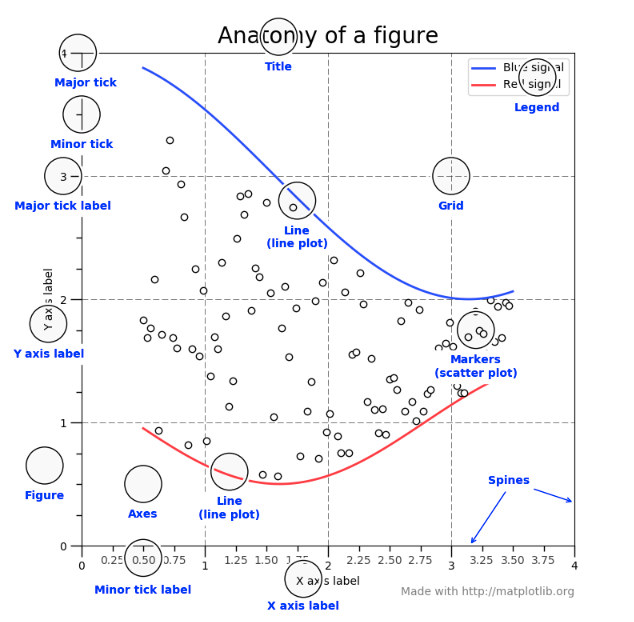

## Key Components of a Plot

- **Figure:**  
  The overall window or canvas on which everything is drawn. Think of it as the entire page.

- **Axes:**  
  The part of the figure that contains the actual plot(s). A figure can contain multiple axes.

- **Title:**  
  The main title of the Axes, describing what the plot represents.

- **X-axis and Y-axis:**  
  The horizontal (X) and vertical (Y) axes with labels that indicate what is being measured.

- **X-axis label & Y-axis label:**  
  Descriptive text for each axis to specify the variable being plotted.

- **Major ticks:**  
  The prominent tick marks along an axis, used to denote main divisions.

- **Minor ticks:**  
  Smaller tick marks that provide additional scale subdivisions between major ticks.

- **Major tick labels & Minor tick labels:**  
  Numeric or textual labels corresponding to the major and minor ticks.

- **Line (Line plot):**  
  A line connecting data points to show trends over a continuous range.

- **Markers (Scatter plot):**  
  Individual points representing specific data values on the plot.

- **Grid:**  
  Lines drawn across the plot to make it easier to read and compare data points.

- **Legend:**  
  A box that explains what each plotted line or marker represents.

- **Spines:**  
  The borders of the plot area (top, bottom, left, right), which can be customized or hidden.


We'll see these components in action shortly.

Let's start with a real dataset, the Automobile dataset from the 1985 Ward's Automotive Yearbook, available on Kaggle (https://www.kaggle.com/toramky/automobile-dataset).

This dataset contains various features for nearly 200 cars, such as the car maker, mileage, dimensions, horsepower, and, most importantly, their price. Our goal will be to understand how these features relate to the car's price.

**Step 1: Loading and Preparing the Data**

First, we'll import the necessary libraries and load the dataset from a URL.

In [1]:
import requests

url = "https://raw.githubusercontent.com/SP9144/FMML_Data/main/Automobile_data.csv"
response = requests.get(url, timeout=30)
response.raise_for_status()


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from io import StringIO
import matplotlib.pyplot as plt

In [3]:
# Loading the dataset
data = StringIO(response.text)
data = pd.read_csv(data)
print("Number of data points =", len(data))
data.head()

Number of data points = 205


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


**Step 2: Data Cleaning**

Real-world data is rarely perfect. If you look at the normalized-losses column, you'll see a '?'. This is a common way to represent missing values. Our code needs to understand that '?' means "no data." We will also remove any rows that have missing values to simplify our analysis for this lab.

In [4]:
# Removing rows which have missing values

data.replace("?", np.nan, inplace = True)
data = data.dropna()
print(len(data))

159


In [5]:
# Dividing the dataset into features (X) and the target variable (y)

X = data.drop("price", axis = 1)
y = pd.to_numeric(data["price"])

We can see that a number of rows with missing data were removed.

**Step 3: Separating Features and Target**

To begin with let's see the plot for Car making company on the X-axis and the price of the car on the Y-axis.

In machine learning, we typically separate our data into two parts:
- Features (X): The input variables we use to make a prediction (e.g., horsepower, make, body-style).
- Target (y): The variable we are trying to predict (in this case, price).



To do this, we use matplotlib.pyplot's scatter() function to create a Scatter Plot for the same.

As far as Machine learning/Data Science is concerned, one of the most commonly used plot for simple data visualization is scatter plots.

This plot gives us a representation of where each points in the entire dataset are present with respect to any 2/3 features (columns). Scatter plots are available in 2-D as well as 3D . The 2-D scatter plot is the important/common one, where we will primarily find patterns/clusters and separability of the data. The code snippet for using a scatter plot is as shown below.

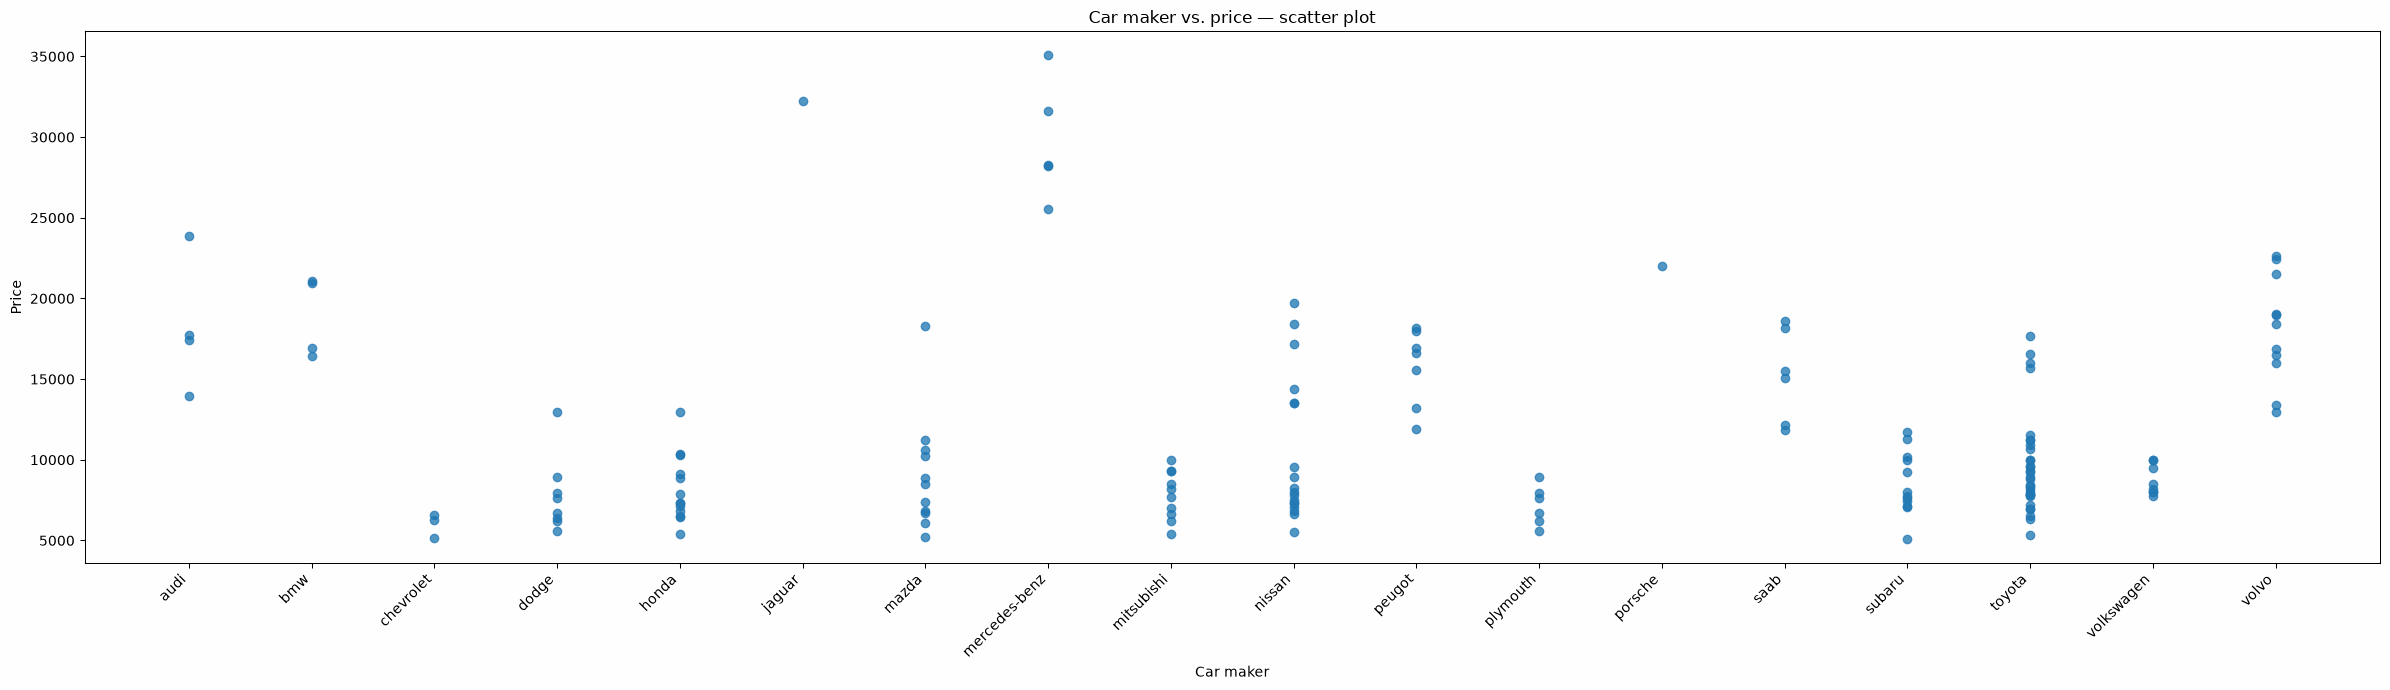

In [6]:
plt.figure(figsize=(24, 7))
plt.scatter(X["make"], y, alpha=0.75)
plt.xlabel("Car maker")
plt.ylabel("Price")
plt.title("Car maker vs. price — scatter plot")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Even though the scatter plot clearly shows that some car makers like Mercedes-benz, Jaguar, Porsche and BMW keep their cars on the higher side of the price range. But is there a better way to understand the distribution of cars within these companies as well?

**A Better View: Statistical Plots with Seaborn**

To get more detailed insights, we'll use Seaborn. Seaborn excels at creating plots that summarize statistical information. Seaborn is a Python data visualization library based on matplotlib.

We will be creating a Box Plot. This is the type of plot that can be used to obtain more of the statistical details about the data. The straight lines at the maximum and minimum are also called as whiskers. Points outside of whiskers will be inferred as an outliers. The box plot gives us a representation of 25th, 50th ,75th quartiles. From a box plot we can also see the Interquartile range(IQR) where maximum details of the data will be present. It also gives us a clear overview of outlier points in the data.

### Here’s how to read it:
- The Box: Represents the central 50% of the data. This is called the Interquartile Range (IQR).
- The Line in the Box: This is the median (or 50th percentile), which represents the middle value of the data.
- The Whiskers: The lines extending from the box show the range of the rest of the data, typically excluding outliers.
- The Dots: Individual points outside the whiskers are considered outliers—unusually high or low values.

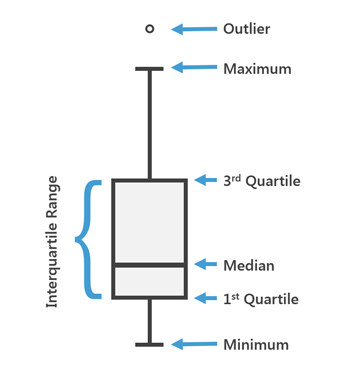

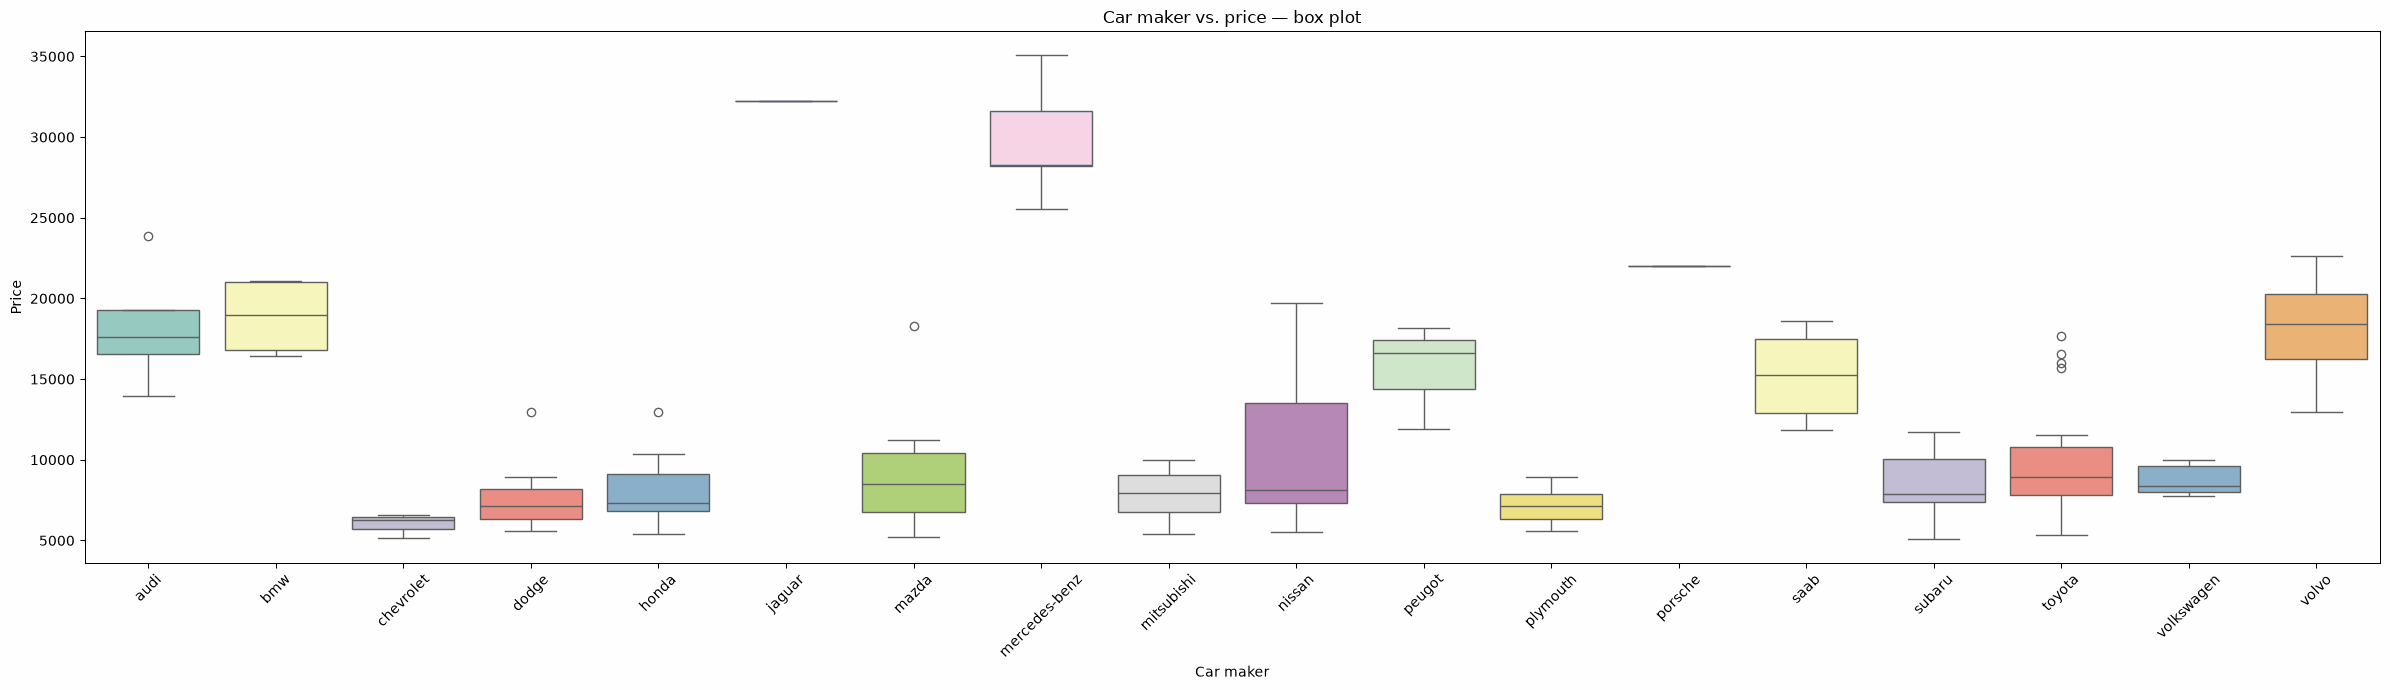

In [7]:
fig, ax = plt.subplots(figsize=(24, 7))
sns.boxplot(data=X, x="make", y=y, hue="make", palette="Set3", dodge=False, legend=False, ax=ax)
ax.set(title="Car maker vs. price — box plot", xlabel="Car maker", ylabel="Price")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()


### Interpretation of the Box Plot

- **High-end brands:** Jaguar has the highest median price in the cleaned sample (32,250), followed by Mercedes-Benz (28,248) and Porsche (22,018). The Jaguar and Porsche groups each contain only one car after cleaning, so their medians are single observations rather than stable brand-wide estimates.
- **Price range:** The box height shows the interquartile range (middle 50% of prices). BMW has a visible spread, but it has only four cleaned cars in this subset; compare group sizes before generalizing.
- **Outliers:** Several makes have high-price points relative to their own distributions. The cleaned data's conventional 1.5-IQR rule flags observations for Audi, Dodge, Honda, Mazda, and Toyota. An outlier is not automatically an error; it may be a distinctive model.

**Conclusion:** The box plot compares typical prices and within-brand spread. Sample sizes matter: a high median based on one car is much less conclusive than a similar pattern in a larger group.


**The Violin Plot: Box Plot + Density**

A Violin Plot is a powerful hybrid. It combines a box plot (visible in the center) with a Kernel Density Estimate (KDE) on each side. The KDE shows the distribution of the data—wider sections mean more data points are concentrated there, while narrower sections mean fewer.We can also use the Violin Plot to understand the distribution within each car maker in a better way.

It also give us useful information like the 95% confidence interval. The below image can help us grasp some important parts from a violin plot.


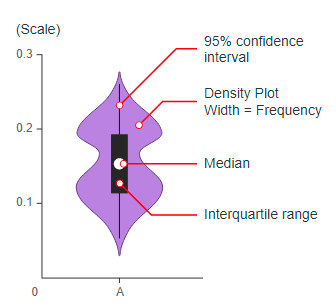

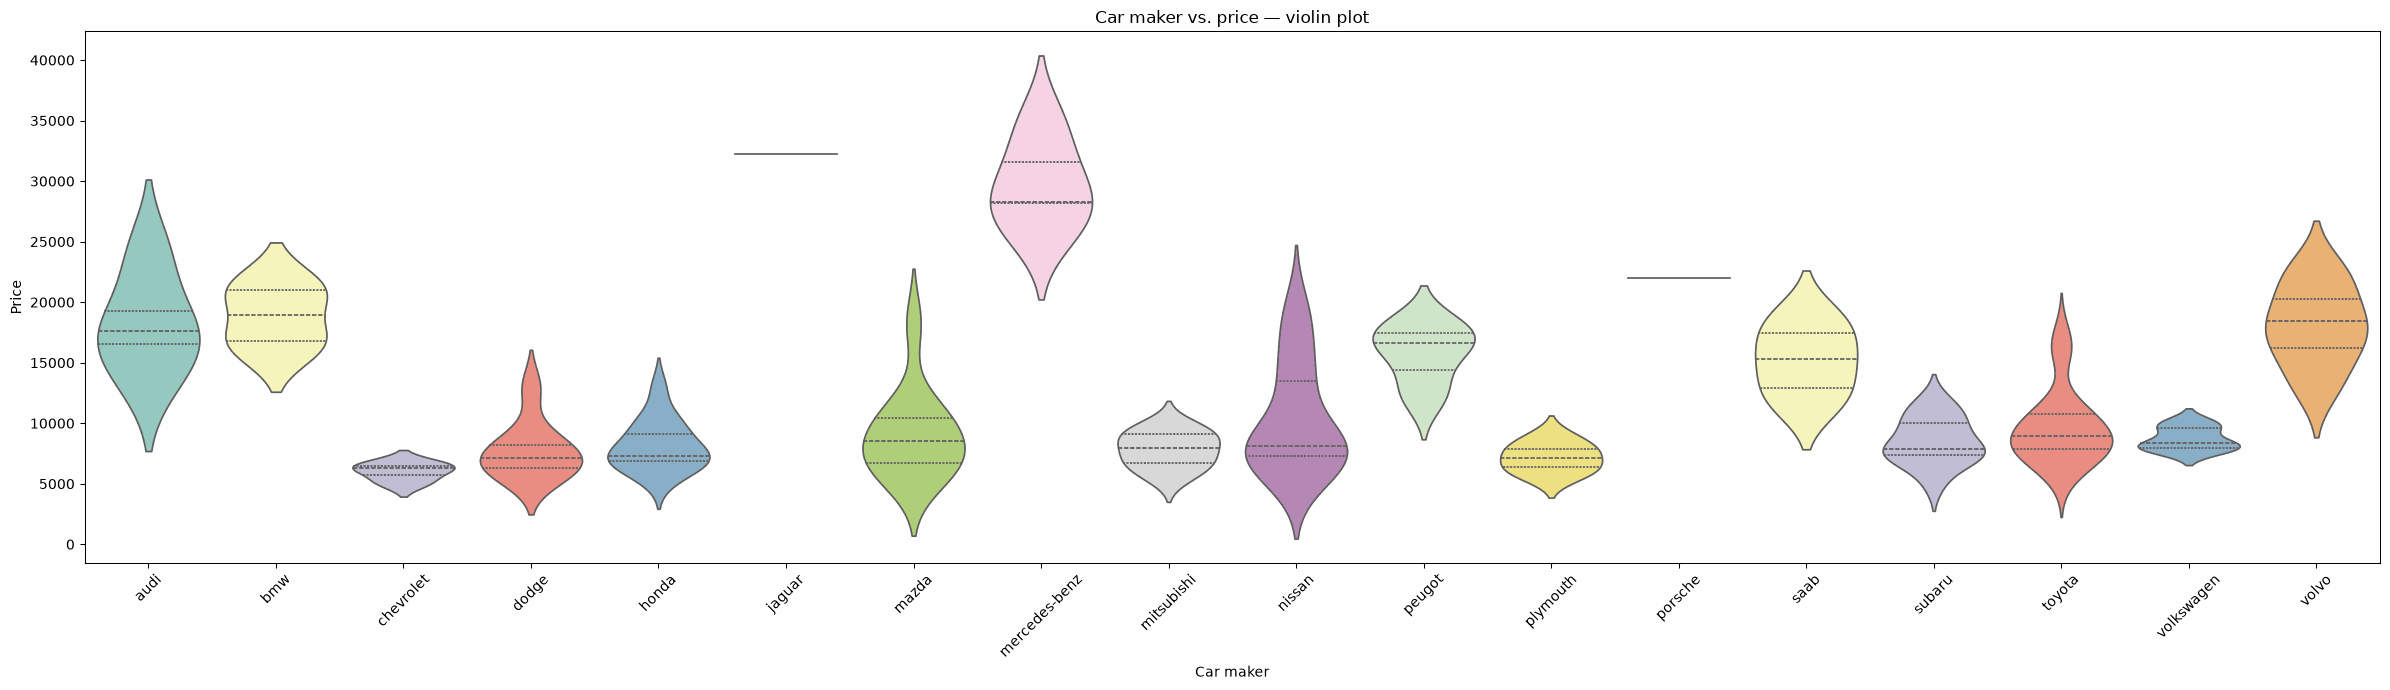

In [8]:
fig, ax = plt.subplots(figsize=(24, 7))
sns.violinplot(data=X, x="make", y=y, hue="make", palette="Set3", dodge=False, legend=False, inner="quart", ax=ax)
ax.set(title="Car maker vs. price — violin plot", xlabel="Car maker", ylabel="Price")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()


### Interpretation of the Violin Plot

Each violin shows the distribution of prices for one manufacturer. Wider sections represent price ranges with more cars; the inner quartile marks show the median and middle half of the data. The plot should be read brand by brand: a violin that is higher on the price axis has more expensive cars, while a wider or longer violin indicates greater variation. The plot complements the box plot by showing the shape of each distribution, including concentrations and tails.


Another plot type are the **Swarm Plots** (Every Point Matters)

A Swarm Plot is like a scatter plot, but it adjusts the position of the points to prevent them from overlapping. This allows you to see the distribution while still plotting every single data point. It's great for smaller datasets where you want to see individual observations. Unlike strip plots, swarm plots attempt to avoid obscuring points by calculating non-overlapping positions instead of adding random jitter. This sort of gives them appearance of a swarm of bees, or perhaps a honeycomb.

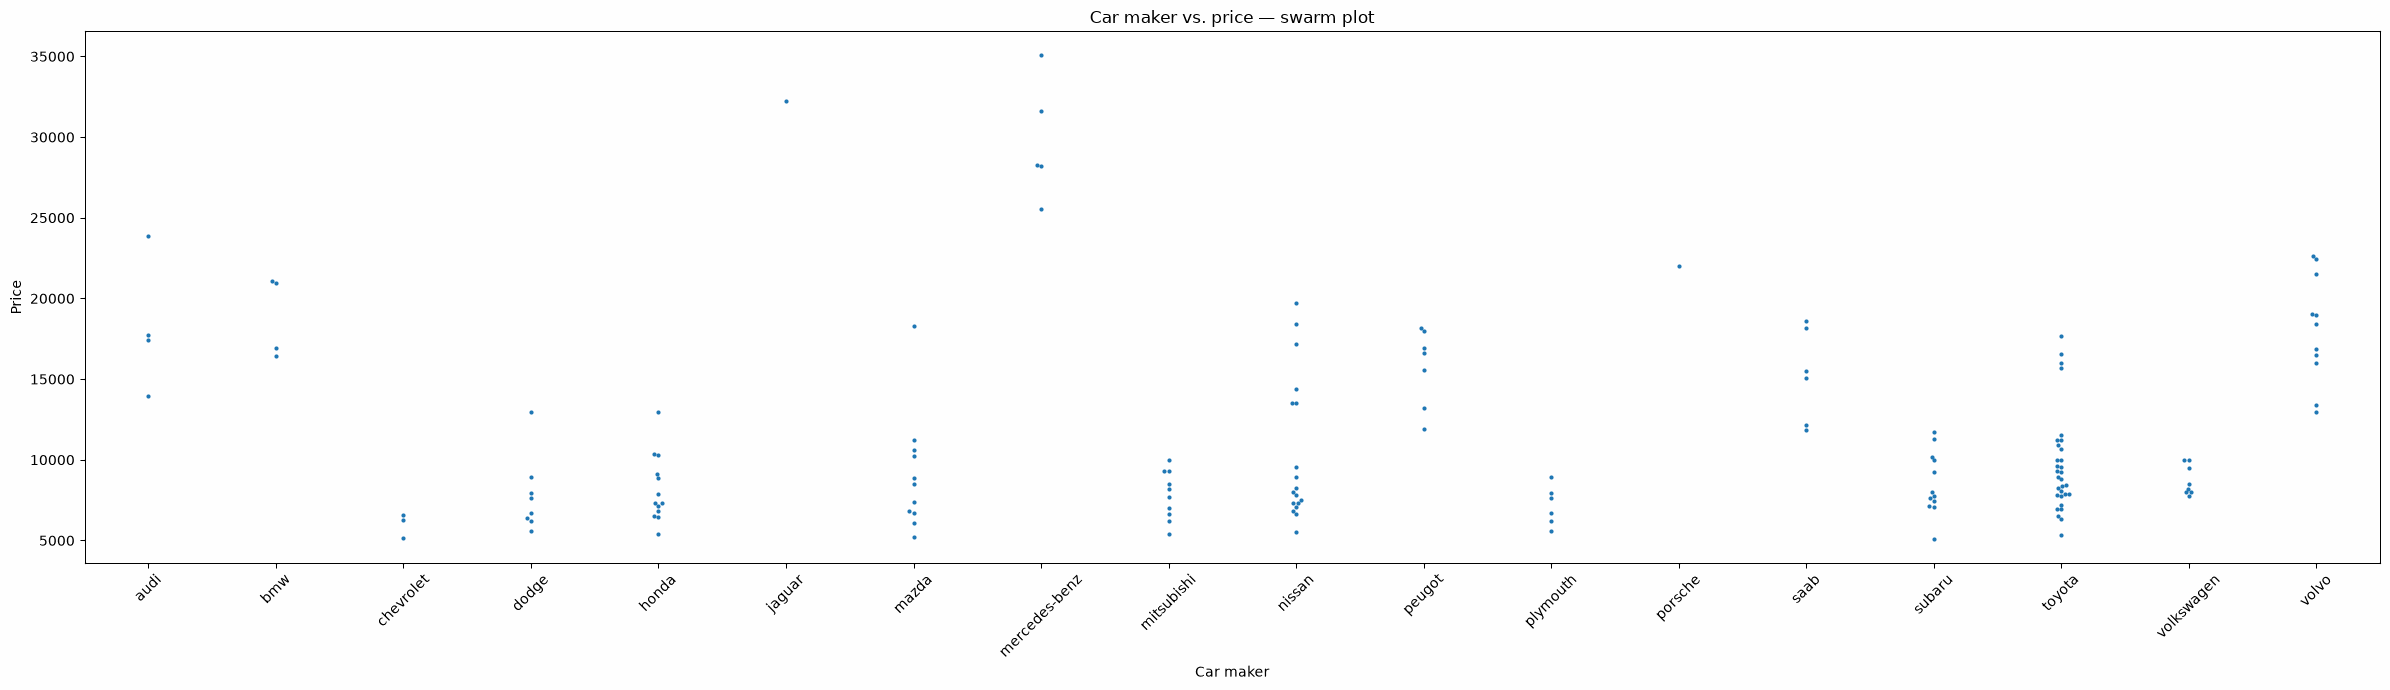

In [9]:
fig, ax = plt.subplots(figsize=(24, 7))
sns.swarmplot(data=X, x="make", y=y, size=3, ax=ax)
ax.set(title="Car maker vs. price — swarm plot", xlabel="Car maker", ylabel="Price")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()


**Note:** This plot can be slow and hard to read for very large datasets, but for our cleaned dataset of 159 cars, it works well.

Now let us try to learn a bit more about the various features in our dataset. One of the features is **Horsepower**, used to describe the power that an engine is capable of producing. A sensible assumption could be that Sport car companies like Porsche would have more cars with higher horsepowers. Lets check if this is actually true ...

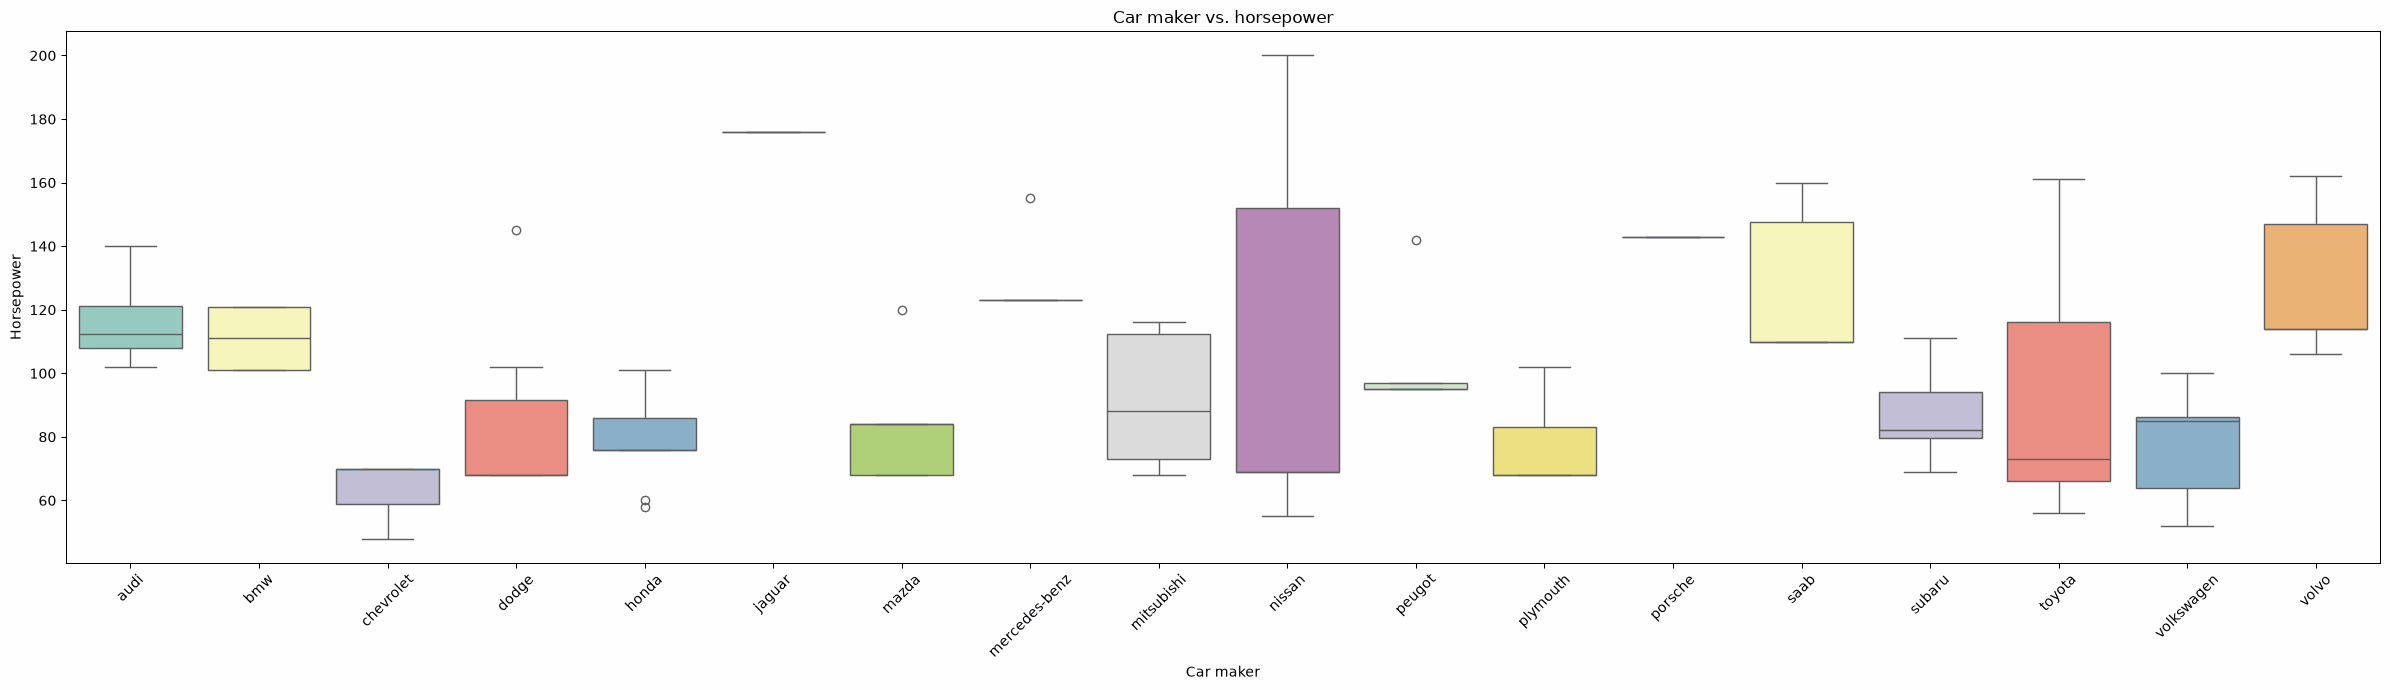

In [10]:
horsepower = pd.to_numeric(X["horsepower"])
fig, ax = plt.subplots(figsize=(24, 7))
sns.boxplot(x=X["make"], y=horsepower, hue=X["make"], palette="Set3", dodge=False, legend=False, ax=ax)
ax.set(title="Car maker vs. horsepower", xlabel="Car maker", ylabel="Horsepower")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()


### Horsepower and price

The scatterplot and regression line show a positive relationship: cars with higher horsepower tend to have higher prices in this cleaned sample. The Pearson correlation is about **0.760**, a strong positive linear association, although points do not fall exactly on a line and correlation does not imply that horsepower alone determines price.


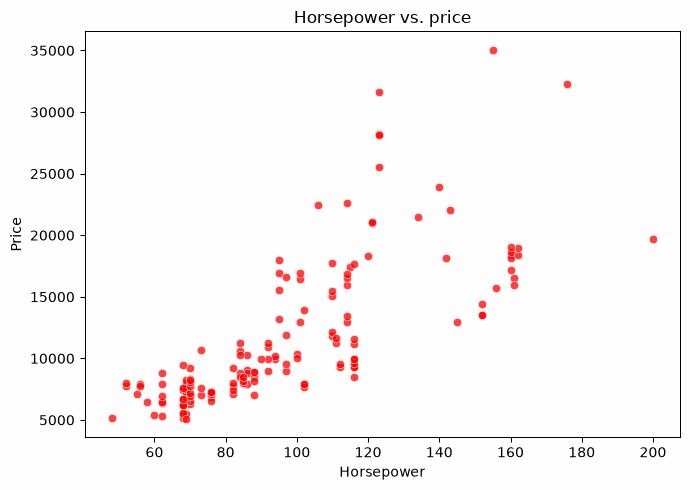

In [11]:
horsepower = pd.to_numeric(X["horsepower"])
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=horsepower, y=y, color="red", alpha=0.75, ax=ax)
ax.set(title="Horsepower vs. price", xlabel="Horsepower", ylabel="Price")
fig.tight_layout()
plt.show()


A better way of plotting these correlations is using a **Jointplot** instead of a simple scatter plot. The jointplot displays a relationship between 2 variables (bivariate) as well as 1D profiles (univariate) in the margins.

I have also used the parameter "reg" which fits a regression line through the points making the correlation sign apparent. A line with positive slope would indicate a postiive correlation and vice versa. A line parallel to x-axis would indicate no correlation between the 2 variables (implying independence).

Pearson correlation (horsepower, price): 0.760


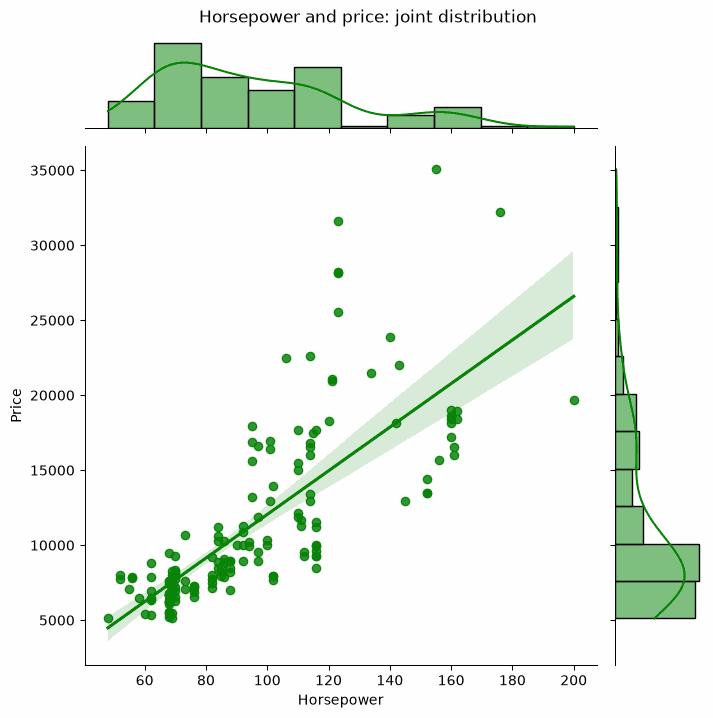

In [12]:
horsepower = pd.to_numeric(X["horsepower"])
g = sns.jointplot(x=horsepower, y=y, kind="reg", color="green", height=7)
g.set_axis_labels("Horsepower", "Price")
g.fig.suptitle("Horsepower and price: joint distribution", y=1.02)
print(f"Pearson correlation (horsepower, price): {horsepower.corr(y):.3f}")
plt.show()


## Exercise: Plot the jointplot for a feature which has negative correlation with the target variable "price".

An example is shown below, with "highway-mpg" where MPG is miles per gallon.

### Hint: You should be using numeric features. The numeric features in the data are listed below:

'symboling', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg'

#### You are motivated to try all of these features to better understand the dataset

Pearson correlation (highway MPG, price): -0.720


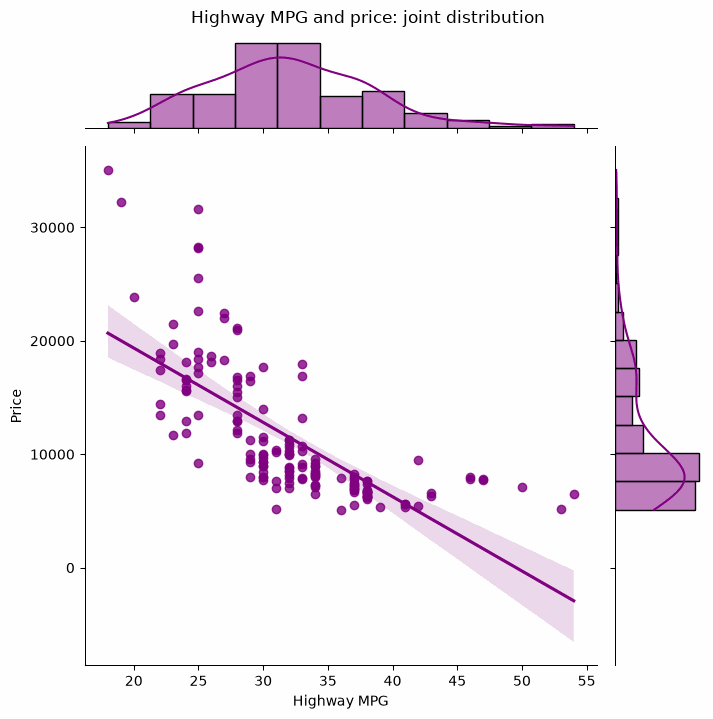

In [13]:
# Highway MPG is the requested numeric feature with a negative relationship to price.
feature = "highway-mpg"
g = sns.jointplot(x=pd.to_numeric(X[feature]), y=y, kind="reg", color="purple", height=7)
g.set_axis_labels("Highway MPG", "Price")
g.fig.suptitle("Highway MPG and price: joint distribution", y=1.02)
print(f"Pearson correlation (highway MPG, price): {pd.to_numeric(X[feature]).corr(y):.3f}")
plt.show()


**Interpretation of highway-MPG vs. price:**

The regression line slopes downward. In this cleaned sample, the Pearson correlation is about **-0.720**, indicating a strong negative linear association: cars with higher highway fuel economy tend to be less expensive. This is a pattern, not a rule for every car, and it does not establish that fuel economy causes a lower price.


## Question: Interpreting Body Style vs. Price
Let's analyze the plot below, which shows the relationship between a car's body-style and its price.

Based on the plot, answer the following questions:

- Which body-type has the highest median price? Which one appears to be the "costliest" overall?
- Is looking only at the maximum value (the top whisker or outlier) a good way to determine the costliest body-style? Why is the interquartile range (the box) a better indicator?
- Do you think the body-style of a car could be a good predictor for its price? Why or why not?


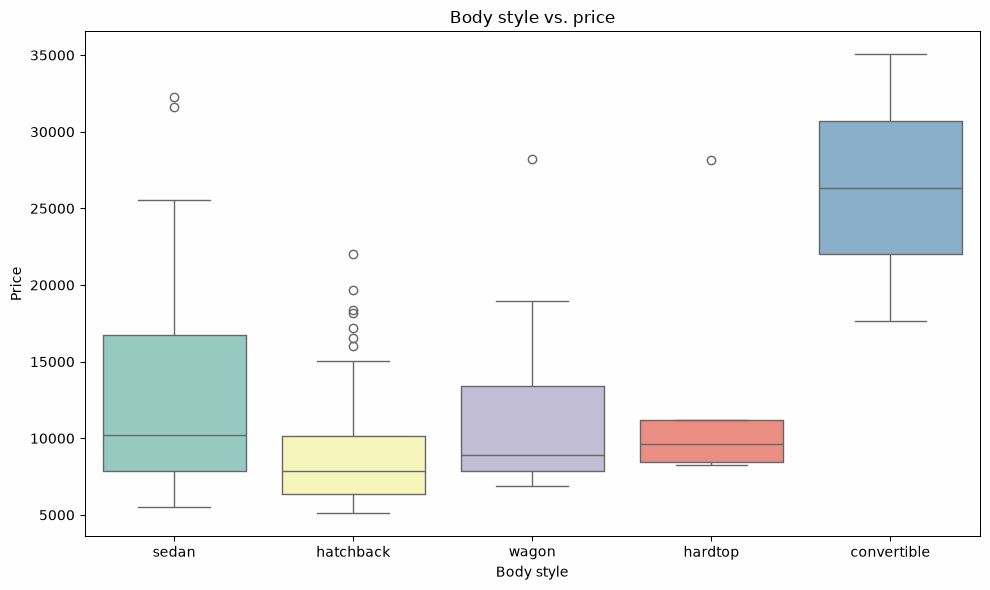

Body-style price summary (dataset currency units):


,count,median,mean,maximum,q1,q3,IQR
body_style,,,,,,,
convertible,2,26362.0,26362.0,35056,22016.0,30709.0,8694.0
sedan,79,10245.0,12559.0,32250,7836.0,16738.0,8901.0
hardtop,5,9639.0,13142.0,28176,8449.0,11199.0,2750.0
wagon,17,8921.0,11351.0,28248,7898.0,13415.0,5517.0
hatchback,56,7847.0,9220.0,22018,6367.0,10140.0,3773.0


In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=X, x="body-style", y=y, hue="body-style", palette="Set3", dodge=False, legend=False, ax=ax)
ax.set(title="Body style vs. price", xlabel="Body style", ylabel="Price")
fig.tight_layout()
plt.show()

body_price = pd.DataFrame({"body_style": X["body-style"].to_numpy(), "price": y.to_numpy()})
body_summary = body_price.groupby("body_style")["price"].agg(
    count="count", median="median", mean="mean", maximum="max",
    q1=lambda values: values.quantile(0.25),
    q3=lambda values: values.quantile(0.75),
)
body_summary["IQR"] = body_summary["q3"] - body_summary["q1"]
print("Body-style price summary (dataset currency units):")
display(body_summary.sort_values("median", ascending=False).round(0))


## Answers: Body Style vs. Price

In the cleaned sample, **convertibles have the highest median price (26,362)** and the highest maximum (35,056). However, there are only two convertibles, so that category estimate is based on very little data. The median is a better description of a typical car than the maximum, because a maximum can be one unusually expensive observation. The interquartile range (IQR) summarizes the middle 50% of prices; a narrow IQR indicates a more concentrated middle, while a wide IQR indicates more variation. The summary table gives the median and IQR for each body style.

Body style can help predict price because group medians and distributions differ, but it cannot determine price by itself: prices overlap across styles and other variables (such as make, engine size, and horsepower) also matter. The relationship shown here is descriptive and does not prove that body style causes a price difference.


### Exercise
Often, you want to display multiple plots side-by-side to compare them. Matplotlib's plt.subplots() function is perfect for this. It creates a figure and a grid of subplots (axes).

**Task:** Choose any 2 plot types discussed above (e.g., a Box Plot and a Violin Plot) and plot them together in a single figure for body-style vs. price.


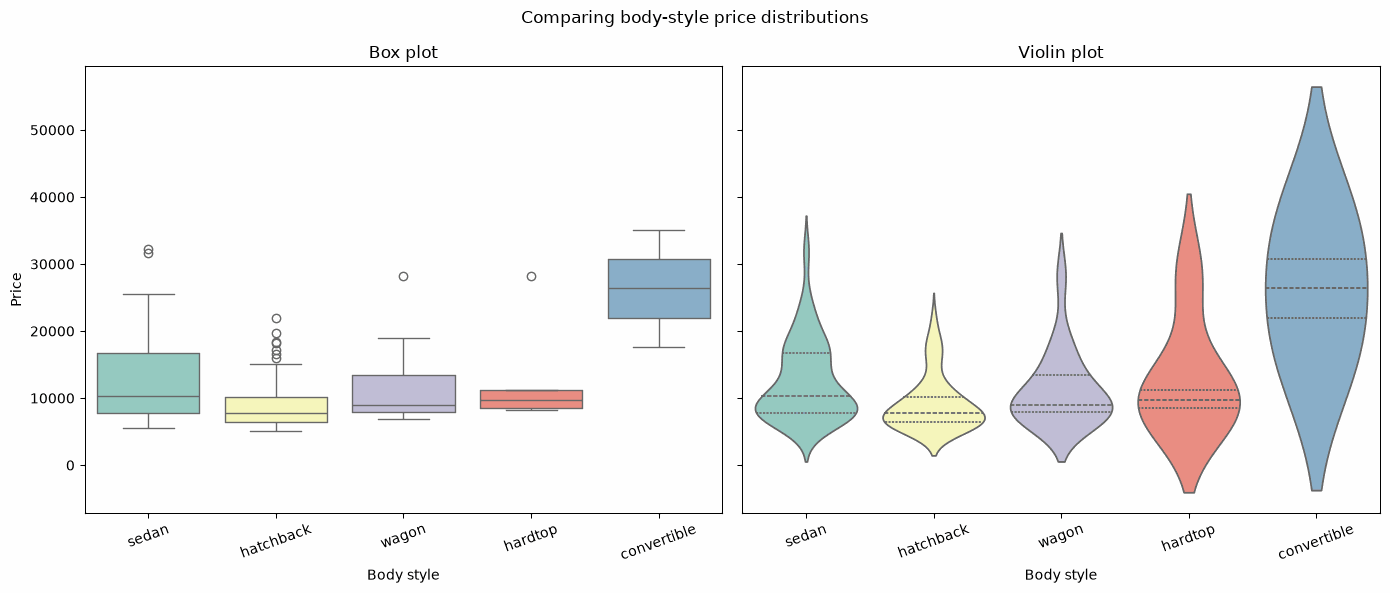

In [15]:
body_plot_data = pd.DataFrame({"body_style": X["body-style"].to_numpy(), "price": y.to_numpy()})
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
sns.boxplot(data=body_plot_data, x="body_style", y="price", hue="body_style", palette="Set3", dodge=False, legend=False, ax=axes[0])
axes[0].set(title="Box plot", xlabel="Body style", ylabel="Price")
sns.violinplot(data=body_plot_data, x="body_style", y="price", hue="body_style", palette="Set3", dodge=False, legend=False, inner="quart", ax=axes[1])
axes[1].set(title="Violin plot", xlabel="Body style", ylabel="Price")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=20)
fig.suptitle("Comparing body-style price distributions")
fig.tight_layout()
plt.show()


The box plot makes the medians, interquartile ranges, and potential outliers easy to compare. The violin plot adds a density shape, showing where prices are concentrated within each body-style group. Reading the two together gives both a robust summary and a view of distribution shape.

Go through the Seaborn documentation and find a plot type that has not been
demonstrated in the examples above. Use this new plot type to represent the above data in a meaningful way.

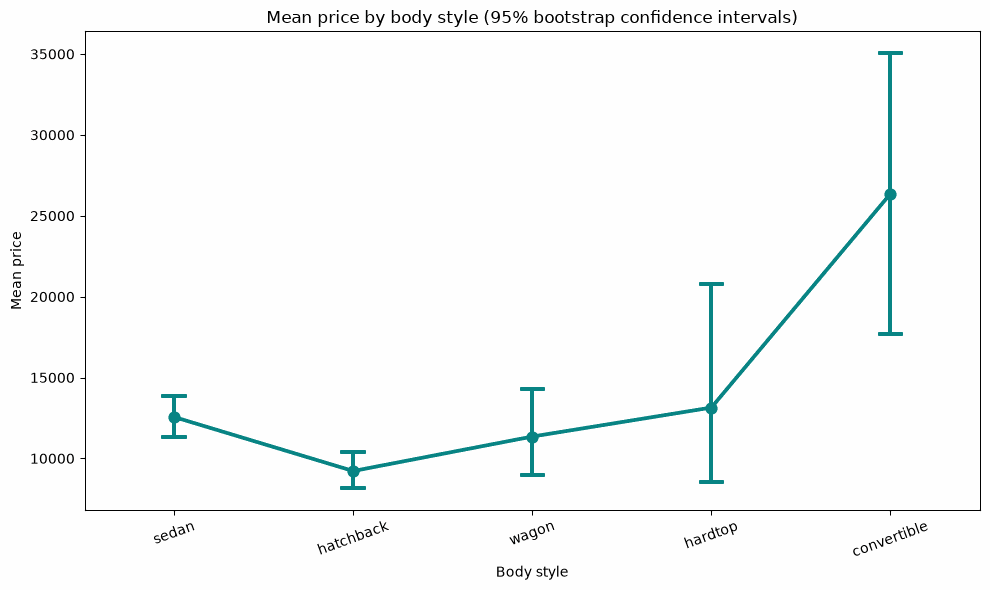

Mean price by body style:


body_style
convertible    26362.0
hardtop        13142.0
sedan          12559.0
wagon          11351.0
hatchback       9220.0
Name: price, dtype: float64

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.pointplot(
    data=body_plot_data,
    x="body_style",
    y="price",
    estimator="mean",
    errorbar=("ci", 95),
    n_boot=1000,
    seed=42,
    capsize=0.12,
    color="teal",
    ax=ax,
)
ax.set(title="Mean price by body style (95% bootstrap confidence intervals)",
       xlabel="Body style", ylabel="Mean price")
ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
plt.show()

print("Mean price by body style:")
display(body_price.groupby("body_style")["price"].mean().sort_values(ascending=False).round(0))


A point plot is a different view from the examples above: each marker is the mean price for a body style, and the vertical bars show 95% bootstrap confidence intervals. In this sample, convertibles have the highest mean price (26,362) and hatchbacks the lowest (9,220), but there are only two convertibles, so the estimate is uncertain. The intervals communicate uncertainty in the estimated means; overlap between intervals is a reason to avoid claiming a clear difference from this plot alone. The point plot emphasizes average levels, so read it alongside the box and violin plots, which show individual spread and distribution shape. This follows Seaborn's documented pointplot behavior ([Seaborn pointplot documentation](https://seaborn.pydata.org/generated/seaborn.pointplot.html)).

Some interesting references:


1) https://towardsdatascience.com/data-visualization-using-matplotlib-16f1aae5ce70

2) https://towardsdatascience.com/data-visualization-for-machine-learning-and-data-science-a45178970be7


3) https://towardsdatascience.com/matplotlib-seaborn-basics-2bd7b66dbee2






